In [1]:
!git clone https://github.com/PanCake31X/SEN12MS-CR-Cloud-Removal.git
import sys
sys.path.append('/kaggle/working/SEN12MS-CR-Cloud-Removal')

!pip install datasets rasterio

fatal: destination path 'SEN12MS-CR-Cloud-Removal' already exists and is not an empty directory.


train.py

In [2]:
import os
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
print("HF_TOKEN loaded into environment.")

HF_TOKEN loaded into environment.


In [3]:
%%writefile /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/flow_matching.py
import math
import torch
import torch.nn as nn
import torch.nn.functional as F


class SinusoidalTimeEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        # t shape: (B, 1, 1, 1) -> (B,)
        t = t.view(-1)
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(half, device=t.device, dtype=torch.float32) / half
        )
        args = t[:, None] * freqs[None, :]
        emb = torch.cat([torch.sin(args), torch.cos(args)], dim=-1)
        return emb


class BidirectionalSS2DBlock(nn.Module):
    """
    4-Way Directional Scanning Block with exact inverse un-scanning,
    long-range dilated 1D gated mixing (O(N) complexity), and FiLM time conditioning.
    """
    def __init__(self, channels, time_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, channels)
        self.time_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(time_dim, channels * 2)
        )
        
        # 4 independent directional 1D depthwise-dilated mixers (long-range context)
        self.dir_convs = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(channels, channels, kernel_size=5, padding=2, groups=channels),
                nn.SiLU(),
                nn.Conv1d(channels, channels, kernel_size=5, padding=6, dilation=3, groups=channels),
            )
            for _ in range(4)
        ])
        
        # Gated projection (Mamba-style multiplicative gating)
        self.gate_proj = nn.Conv2d(channels, channels, kernel_size=1)
        self.out_proj = nn.Conv2d(channels, channels, kernel_size=1)
        
        # Feed-forward channel mixer
        self.norm2 = nn.GroupNorm(8, channels)
        self.ffn = nn.Sequential(
            nn.Conv2d(channels, channels * 2, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(channels * 2, channels, kernel_size=1)
        )

    def forward(self, x, t_emb):
        B, C, H, W = x.shape
        h = self.norm1(x)
        
        # FiLM time modulation: scale & shift
        scale, shift = self.time_mlp(t_emb).chunk(2, dim=1)
        h = h * (1.0 + scale[:, :, None, None]) + shift[:, :, None, None]
        
        gate = F.silu(self.gate_proj(h))
        
        # 4-way scan + EXACT inverse un-scan so every (h, w) aligns 1-to-1
        # 1. Row-major forward
        s1 = self.dir_convs[0](h.flatten(2)).view(B, C, H, W)
        # 2. Row-major backward
        s2 = self.dir_convs[1](h.flatten(2).flip(-1)).flip(-1).view(B, C, H, W)
        # 3. Col-major forward
        h_t = h.transpose(2, 3).contiguous()
        s3 = self.dir_convs[2](h_t.flatten(2)).view(B, C, W, H).transpose(2, 3)
        # 4. Col-major backward
        s4 = self.dir_convs[3](h_t.flatten(2).flip(-1)).flip(-1).view(B, C, W, H).transpose(2, 3)
        
        fused = (s1 + s2 + s3 + s4) * 0.25
        x = x + self.out_proj(fused * gate)
        x = x + self.ffn(self.norm2(x))
        return x


class MambaVectorFieldPredictor(nn.Module):
    """
    Production-grade Multi-Scale SS2D Velocity Predictor for Latent Flow Matching.
    """
    def __init__(self, latent_dim=8, hidden_dim=128):
        super().__init__()
        time_dim = hidden_dim * 2
        self.time_embed = nn.Sequential(
            SinusoidalTimeEmb(hidden_dim),
            nn.Linear(hidden_dim, time_dim),
            nn.SiLU(),
            nn.Linear(time_dim, time_dim)
        )
        
        # Concatenate z_t (8) + condition_sar (8) = 16 channels
        self.in_proj = nn.Conv2d(latent_dim * 2, hidden_dim, kernel_size=3, padding=1)
        
        # Encoder (32x32 -> 16x16)
        self.enc1 = BidirectionalSS2DBlock(hidden_dim, time_dim)
        self.down = nn.Conv2d(hidden_dim, hidden_dim * 2, kernel_size=3, stride=2, padding=1)
        
        # Bottleneck (16x16)
        self.mid1 = BidirectionalSS2DBlock(hidden_dim * 2, time_dim)
        self.mid2 = BidirectionalSS2DBlock(hidden_dim * 2, time_dim)
        
        # Decoder (16x16 -> 32x32)
        self.up = nn.ConvTranspose2d(hidden_dim * 2, hidden_dim, kernel_size=4, stride=2, padding=1)
        self.skip_fuse = nn.Conv2d(hidden_dim * 2, hidden_dim, kernel_size=1)
        self.dec1 = BidirectionalSS2DBlock(hidden_dim, time_dim)
        
        # Output velocity projection (zero-initialized for stable start)
        self.out_norm = nn.GroupNorm(8, hidden_dim)
        self.out_proj = nn.Conv2d(hidden_dim, latent_dim, kernel_size=3, padding=1)
        nn.init.zeros_(self.out_proj.weight)
        nn.init.zeros_(self.out_proj.bias)

    def forward(self, z_t, t, condition_sar):
        t_emb = self.time_embed(t)
        
        x = torch.cat([z_t, condition_sar], dim=1)
        h0 = self.in_proj(x)
        
        h1 = self.enc1(h0, t_emb)          # (B, 128, 32, 32)
        h_down = self.down(h1)             # (B, 256, 16, 16)
        
        m = self.mid1(h_down, t_emb)       # (B, 256, 16, 16)
        m = self.mid2(m, t_emb)            # (B, 256, 16, 16)
        
        u = self.up(m)                     # (B, 128, 32, 32)
        u = self.skip_fuse(torch.cat([u, h1], dim=1))
        out = self.dec1(u, t_emb)          # (B, 128, 32, 32)
        
        return self.out_proj(F.silu(self.out_norm(out)))


class FlowMatchingLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.mse = nn.MSELoss()

    def forward(self, z_clear, z_cloudy, predictor, condition_sar):
        B = z_clear.shape[0]
        device = z_clear.device
        
        t = torch.rand(B, 1, 1, 1, device=device)
        z_t = (1.0 - t) * z_clear + t * z_cloudy
        true_velocity = z_cloudy - z_clear
        
        predicted_velocity = predictor(z_t, t, condition_sar)
        loss = self.mse(predicted_velocity, true_velocity)
        return loss, predicted_velocity, true_velocity

Overwriting /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/flow_matching.py


In [4]:
%%writefile /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/inference.py
import torch
import torch.nn as nn

LATENT_SCALE = 3.0

class MultiStepODESolver(nn.Module):
    """
    Executes N-step Euler integration from t=1 (cloudy) to t=0 (clear)
    in unit-variance latent space.
    """
    def __init__(self, steps=10):
        super().__init__()
        self.steps = steps

    def forward(self, z_cloudy, condition_sar, predictor):
        B = z_cloudy.shape[0]
        device = z_cloudy.device
        
        z = z_cloudy.clone()
        dt = 1.0 / self.steps
        
        for s in range(self.steps):
            t_curr = torch.full((B, 1, 1, 1), 1.0 - s * dt, device=device)
            v = predictor(z, t_curr, condition_sar)
            z = z - v * dt
            
        return z

class SARGuidedCloudRemovalPipeline(nn.Module):
    def __init__(self, vae, predictor, steps=10):
        super().__init__()
        self.vae = vae
        self.predictor = predictor
        self.solver = MultiStepODESolver(steps=steps)

    def forward(self, opt_cloudy, sar_norm):
        z_cloudy = self.vae.encode_optical(opt_cloudy) / LATENT_SCALE
        z_sar = self.vae.encode_sar(sar_norm)
        
        z_clear_pred = self.solver(z_cloudy, z_sar, self.predictor)
        opt_clear_pred = self.vae.decode(z_clear_pred * LATENT_SCALE)
        return opt_clear_pred

Overwriting /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/inference.py


In [5]:
%%writefile /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/refiner.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import spectral_norm


class ResConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.skip = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x):
        h = F.silu(self.norm1(self.conv1(x)))
        h = self.norm2(self.conv2(h))
        return F.silu(h + self.skip(x))


class RefinementUNetV3(nn.Module):
    """
    256x256 Mask-Gated Residual Refiner.
    - Backbone + mask_head warm-start cleanly from RefinementUNetV2.
    - Clear regions (1 - M) receive only a low-frequency bounded color shift,
      physically preventing the refiner from blurring clear optical detail.
    - Cloud regions (M) receive full high-frequency SAR-guided reconstruction.
    """
    def __init__(self, base_ch=48):
        super().__init__()
        in_channels = 4 + 13 + 2 + 2  # stage1 + 13-band optical + raw SAR + 5x5 SAR

        # Encoder: 256 -> 128 -> 64 -> 32
        self.enc1 = ResConvBlock(in_channels, base_ch)
        self.down1 = nn.Conv2d(base_ch, base_ch * 2, kernel_size=3, stride=2, padding=1)
        self.enc2 = ResConvBlock(base_ch * 2, base_ch * 2)
        self.down2 = nn.Conv2d(base_ch * 2, base_ch * 4, kernel_size=3, stride=2, padding=1)
        self.enc3 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.down3 = nn.Conv2d(base_ch * 4, base_ch * 4, kernel_size=3, stride=2, padding=1)

        # Bottleneck: 32x32
        self.mid1 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.mid2 = ResConvBlock(base_ch * 4, base_ch * 4)

        # Decoder: 32 -> 64 -> 128 -> 256
        self.up3 = nn.ConvTranspose2d(base_ch * 4, base_ch * 4, kernel_size=4, stride=2, padding=1)
        self.dec3 = ResConvBlock(base_ch * 8, base_ch * 4)
        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, kernel_size=4, stride=2, padding=1)
        self.dec2 = ResConvBlock(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, kernel_size=4, stride=2, padding=1)
        self.dec1 = ResConvBlock(base_ch * 2, base_ch)

        # Soft cloud mask head (loaded from v2)
        self.mask_head = nn.Conv2d(base_ch, 1, kernel_size=3, padding=1)
        nn.init.zeros_(self.mask_head.weight)
        nn.init.constant_(self.mask_head.bias, 2.0)

        # Zero-initialized cloud-only high-frequency residual
        self.delta_cloud = nn.Conv2d(base_ch, 4, kernel_size=3, padding=1)
        nn.init.zeros_(self.delta_cloud.weight)
        nn.init.zeros_(self.delta_cloud.bias)

        # Zero-initialized low-frequency color/exposure correction for clear pixels
        self.color_head = nn.Conv2d(base_ch, 4, kernel_size=1)
        nn.init.zeros_(self.color_head.weight)
        nn.init.zeros_(self.color_head.bias)

    def forward(self, stage1_pred, opt_cloudy_13, sar_norm):
        sar_5x5 = F.avg_pool2d(sar_norm, kernel_size=5, stride=1, padding=2)
        x = torch.cat([stage1_pred, opt_cloudy_13, sar_norm, sar_5x5], dim=1)

        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        m = self.mid2(self.mid1(self.down3(e3)))

        d3 = self.dec3(torch.cat([self.up3(m), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        mask = torch.sigmoid(self.mask_head(d1))
        delta_cloud = self.delta_cloud(d1)

        # 17x17 low-pass guarantees clear-pixel color adjustment cannot blur fine edges
        d1_lowfreq = F.avg_pool2d(d1, kernel_size=17, stride=1, padding=8)
        delta_color = 0.15 * torch.tanh(self.color_head(d1_lowfreq))

        opt_cloudy_4 = opt_cloudy_13[:, [1, 2, 3, 7], :, :]
        clear_branch = opt_cloudy_4 + delta_color
        cloud_branch = stage1_pred + delta_cloud

        out = (1.0 - mask) * clear_branch + mask * cloud_branch
        return torch.clamp(out, -1.0, 1.0)


class ConditionalPatchDiscriminator(nn.Module):
    """
    Spectral-Norm PatchGAN Discriminator conditioned on 5x5 despeckled SAR.
    No BatchNorm -> completely stable at batch_size=1.
    Input: [opt_4 (4), sar_5x5 (2)] = 6 channels -> 30x30 patch realism logits.
    """
    def __init__(self, in_channels=6, base_ch=64):
        super().__init__()
        self.net = nn.Sequential(
            spectral_norm(nn.Conv2d(in_channels, base_ch, kernel_size=4, stride=2, padding=1)),
            nn.LeakyReLU(0.2, inplace=True),
            spectral_norm(nn.Conv2d(base_ch, base_ch * 2, kernel_size=4, stride=2, padding=1)),
            nn.LeakyReLU(0.2, inplace=True),
            spectral_norm(nn.Conv2d(base_ch * 2, base_ch * 4, kernel_size=4, stride=2, padding=1)),
            nn.LeakyReLU(0.2, inplace=True),
            spectral_norm(nn.Conv2d(base_ch * 4, base_ch * 4, kernel_size=4, stride=1, padding=1)),
            nn.LeakyReLU(0.2, inplace=True),
            spectral_norm(nn.Conv2d(base_ch * 4, 1, kernel_size=4, stride=1, padding=1)),
        )

    def forward(self, opt_4, sar_5x5):
        return self.net(torch.cat([opt_4, sar_5x5], dim=1))

Overwriting /kaggle/working/SEN12MS-CR-Cloud-Removal/src/models/refiner.py


In [ ]:
%%writefile /kaggle/working/SEN12MS-CR-Cloud-Removal/src/train_stage2_refiner.py
import os
import gc
import sys
import copy
import glob
import math
import time
import traceback
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision.models as tv_models
import numpy as np
import pyarrow as pa
from datasets import load_dataset
from torch.amp import autocast, GradScaler

from src.models.latent_compression import SatelliteVAE
from src.models.flow_matching import MambaVectorFieldPredictor
from src.models.inference import SARGuidedCloudRemovalPipeline
from src.models.refiner import RefinementUNetV3, ConditionalPatchDiscriminator


def get_ram_gb():
    try:
        with open("/proc/self/status") as f:
            for line in f:
                if line.startswith("VmRSS:"):
                    return int(line.split()[1]) / (1024.0 * 1024.0)
    except Exception:
        pass
    return -1.0


class MultiLayerVGGPerceptualLoss(nn.Module):
    """Frozen multi-scale VGG16 loss (relu1_2, relu2_2, relu3_3) on 2.5x gained RGB."""
    def __init__(self):
        super().__init__()
        vgg_full = tv_models.vgg16(weights=tv_models.VGG16_Weights.DEFAULT)
        self.blocks = nn.ModuleList([
            copy.deepcopy(vgg_full.features[:4]).eval(),
            copy.deepcopy(vgg_full.features[4:9]).eval(),
            copy.deepcopy(vgg_full.features[9:16]).eval(),
        ])
        del vgg_full
        gc.collect()
        for p in self.blocks.parameters():
            p.requires_grad = False
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, pred, target):
        p = (torch.clamp((pred[:, [2, 1, 0]].float() + 1.0) * 0.5 * 2.5, 0.0, 1.0) - self.mean) / self.std
        t = (torch.clamp((target[:, [2, 1, 0]].float() + 1.0) * 0.5 * 2.5, 0.0, 1.0) - self.mean) / self.std
        loss = 0.0
        for blk in self.blocks:
            p = blk(p)
            t = blk(t)
            loss = loss + F.l1_loss(p, t)
        return loss / len(self.blocks)


def fft_amplitude_loss(pred, target):
    fp = torch.fft.rfft2(pred.float(), norm="ortho")
    ft = torch.fft.rfft2(target.float(), norm="ortho")
    return F.l1_loss(torch.log1p(fp.abs()), torch.log1p(ft.abs()))


def format_hf_sample(sample, device):
    sar = np.frombuffer(sample["sar"], dtype=np.float32).reshape(sample["sar_shape"])
    cloudy = np.frombuffer(sample["cloudy"], dtype=np.int16).reshape(sample["opt_shape"])
    clear = np.frombuffer(sample["target"], dtype=np.int16).reshape(sample["opt_shape"])

    sar_tensor = torch.from_numpy(sar.copy()).float()
    if sar_tensor.shape[-1] == 2:
        sar_tensor = sar_tensor.permute(2, 0, 1)
    sar_tensor = (torch.clamp(sar_tensor, -25.0, 0.0) / 12.5 + 1.0).unsqueeze(0).to(device, non_blocking=True)

    cloudy_13 = torch.from_numpy(cloudy.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device, non_blocking=True) / 10000.0
    clear_13 = torch.from_numpy(clear.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device, non_blocking=True) / 10000.0

    opt_cloudy_13 = torch.clamp(cloudy_13, 0.0, 1.0) * 2.0 - 1.0
    opt_clear_4 = (torch.clamp(clear_13, 0.0, 1.0) * 2.0 - 1.0)[:, [1, 2, 3, 7], :, :]

    return sar_tensor, opt_cloudy_13, opt_clear_4


@torch.no_grad()
def update_ema(ema_mod, live_mod, decay=0.998):
    for p_ema, p_live in zip(ema_mod.parameters(), live_mod.parameters()):
        p_ema.data.mul_(decay).add_(p_live.data, alpha=1.0 - decay)


def build_stream(seed):
    ds = load_dataset("Hermanni/sen12mscr", split="train", streaming=True)
    return iter(ds.shuffle(buffer_size=500, seed=seed))


def train_stage2_v3():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Executing Stage 2 v3 (Mask-Gated + SAR-PatchGAN + MultiLayerVGG/FFT) on: {device}", flush=True)

    matches = glob.glob("/kaggle/**/mamba_flow_stage2_v2_FINAL.pth", recursive=True)
    if not matches:
        raise FileNotFoundError(
            "mamba_flow_stage2_v2_FINAL.pth not found in /kaggle/input. "
            "Attach your v2 weights dataset before committing."
        )
    v2_path = matches[0]
    print(f"Warm-starting Stage 1 + Refiner backbone/mask from: {v2_path}", flush=True)

    vae = SatelliteVAE(opt_channels=4, sar_channels=2, latent_dim=8).to(device)
    predictor = MambaVectorFieldPredictor(latent_dim=8, hidden_dim=128).to(device)
    refiner = RefinementUNetV3(base_ch=48).to(device)

    ckpt = torch.load(v2_path, map_location="cpu", weights_only=True)
    vae_state_cpu = ckpt["vae_state"]
    pred_state_cpu = ckpt["predictor_state"]
    vae.load_state_dict(vae_state_cpu)
    predictor.load_state_dict(pred_state_cpu)

    missing, unexpected = refiner.load_state_dict(ckpt["refiner_state"], strict=False)
    print(f"Refiner warm-start | New heads (zero-init): {missing} | Dropped v2 heads: {unexpected}", flush=True)
    del ckpt
    gc.collect()

    stage1 = SARGuidedCloudRemovalPipeline(vae, predictor, steps=10).to(device).eval()
    for p in stage1.parameters():
        p.requires_grad = False

    ema_refiner = copy.deepcopy(refiner).eval()
    disc = ConditionalPatchDiscriminator(in_channels=6, base_ch=64).to(device)

    total_samples = 20000
    accumulation_steps = 4
    total_opt_steps = total_samples // accumulation_steps  # 5,000 updates
    warmup_steps = 250

    opt_g = optim.AdamW(refiner.parameters(), lr=1.5e-4, betas=(0.5, 0.999), weight_decay=1e-4)
    opt_d = optim.AdamW(disc.parameters(), lr=2.0e-4, betas=(0.5, 0.999), weight_decay=1e-4)

    def lr_lambda(opt_step):
        if opt_step < warmup_steps:
            return float(opt_step + 1) / float(warmup_steps)
        progress = (opt_step - warmup_steps) / max(1, total_opt_steps - warmup_steps)
        return 0.1 + 0.9 * 0.5 * (1.0 + math.cos(math.pi * progress))

    sched_g = optim.lr_scheduler.LambdaLR(opt_g, lr_lambda)
    sched_d = optim.lr_scheduler.LambdaLR(opt_d, lr_lambda)

    scaler_g = GradScaler('cuda')
    scaler_d = GradScaler('cuda')
    vgg_fn = MultiLayerVGGPerceptualLoss().to(device)

    seed = 4042
    iterator = build_stream(seed)
    opt_g.zero_grad()
    opt_d.zero_grad()

    r_l1, r_vgg, r_fft, r_gadv, r_dloss, valid_count = 0.0, 0.0, 0.0, 0.0, 0.0, 0
    accum_valid = 0
    consecutive_errors = 0

    for step in range(1, total_samples + 1):
        while True:
            try:
                if iterator is None:
                    iterator = build_stream(seed)
                sample = next(iterator)
                sar_t, opt_cloudy_13, opt_clear_4 = format_hf_sample(sample, device)
                del sample
                consecutive_errors = 0
                break
            except StopIteration:
                seed += 1
                iterator = None
            except Exception as e:
                consecutive_errors += 1
                print(f"[Stream Warning] Step {step}: {e} (Retry {consecutive_errors}/10)", flush=True)
                if consecutive_errors >= 10:
                    raise RuntimeError("Exceeded 10 consecutive stream failures.")
                time.sleep(5)
                seed += 1
                iterator = None

        opt_cloudy_4 = opt_cloudy_13[:, [1, 2, 3, 7], :, :]
        sar_5x5 = F.avg_pool2d(sar_t, kernel_size=5, stride=1, padding=2)

        # Ramp adversarial weight: 0 for first 1k samples (D warmup), -> 0.015 by 3k
        if step <= 1000:
            adv_w = 0.0
        elif step <= 3000:
            adv_w = 0.015 * (step - 1000) / 2000.0
        else:
            adv_w = 0.015

        # --- 1. Generator Forward & Backward ---
        for p in disc.parameters():
            p.requires_grad = False

        with autocast('cuda'):
            with torch.no_grad():
                stage1_pred = stage1(opt_cloudy_4, sar_t).clamp(-1.0, 1.0)

            refined = refiner(stage1_pred, opt_cloudy_13, sar_t)
            l1 = F.l1_loss(refined, opt_clear_4)
            vgg = vgg_fn(refined, opt_clear_4)
            fft = fft_amplitude_loss(refined, opt_clear_4)

            if adv_w > 0.0:
                g_adv = -disc(refined, sar_5x5).mean()
            else:
                g_adv = torch.zeros((), device=device)

            loss_g = (l1 + 0.20 * vgg + 2.0 * fft + adv_w * g_adv) / accumulation_steps

        if not torch.isfinite(loss_g):
            opt_g.zero_grad()
            opt_d.zero_grad()
            accum_valid = 0
            continue

        scaler_g.scale(loss_g).backward()

        # --- 2. Discriminator Forward & Backward (Hinge Loss) ---
        for p in disc.parameters():
            p.requires_grad = True

        with autocast('cuda'):
            d_real = disc(opt_clear_4, sar_5x5)
            d_fake = disc(refined.detach(), sar_5x5)
            loss_d = (F.relu(1.0 - d_real).mean() + F.relu(1.0 + d_fake).mean()) / accumulation_steps

        if not torch.isfinite(loss_d):
            opt_g.zero_grad()
            opt_d.zero_grad()
            accum_valid = 0
            continue

        scaler_d.scale(loss_d).backward()

        r_l1 += l1.item()
        r_vgg += vgg.item()
        r_fft += fft.item()
        r_gadv += g_adv.item()
        r_dloss += (loss_d.item() * accumulation_steps)
        valid_count += 1
        accum_valid += 1

        if step % accumulation_steps == 0 and accum_valid > 0:
            scaler_g.unscale_(opt_g)
            torch.nn.utils.clip_grad_norm_(refiner.parameters(), 0.5)
            scaler_g.step(opt_g)
            scaler_g.update()
            sched_g.step()
            opt_g.zero_grad()

            scaler_d.unscale_(opt_d)
            torch.nn.utils.clip_grad_norm_(disc.parameters(), 1.0)
            scaler_d.step(opt_d)
            scaler_d.update()
            sched_d.step()
            opt_d.zero_grad()

            update_ema(ema_refiner, refiner, decay=0.998)
            accum_valid = 0

        if step % 500 == 0:
            gc.collect()
            pa.default_memory_pool().release_unused()

        if step % 1000 == 0 and valid_count > 0:
            lr_now = sched_g.get_last_lr()[0]
            print(
                f"Sample {step:5d}/{total_samples} | "
                f"L1: {r_l1/valid_count:.4f} | "
                f"VGG: {r_vgg/valid_count:.4f} | "
                f"FFT: {r_fft/valid_count:.4f} | "
                f"G_adv: {r_gadv/valid_count:+.3f} | "
                f"D_hinge: {r_dloss/valid_count:.3f} | "
                f"LR: {lr_now:.6f} | RAM: {get_ram_gb():.2f} GB",
                flush=True
            )
            r_l1, r_vgg, r_fft, r_gadv, r_dloss, valid_count = 0.0, 0.0, 0.0, 0.0, 0.0, 0

        if step % 5000 == 0:
            ckpt_out = f"/kaggle/working/mamba_flow_stage2_v3_step_{step}.pth"
            torch.save({
                'refiner_state': ema_refiner.state_dict(),
                'raw_refiner_state': refiner.state_dict(),
                'disc_state': disc.state_dict(),
                'step': step,
            }, ckpt_out)
            print(f"Checkpoint saved: {ckpt_out}", flush=True)

    final_path = "/kaggle/working/mamba_flow_stage2_v3_FINAL.pth"
    torch.save({
        'vae_state': vae_state_cpu,
        'predictor_state': pred_state_cpu,
        'refiner_state': ema_refiner.state_dict(),
        'step': total_samples,
    }, final_path)
    print(f"Stage 2 v3 Complete. All-in-one weights saved to {final_path}", flush=True)
    sys.stdout.flush()
    os._exit(0)


if __name__ == "__main__":
    try:
        train_stage2_v3()
    except Exception:
        traceback.print_exc()
        sys.stdout.flush()
        sys.stderr.flush()
        os._exit(1)

In [ ]:
import subprocess
subprocess.run(
    ["python", "-u", "-m", "src.train_stage2_refiner"],
    cwd="/kaggle/working/SEN12MS-CR-Cloud-Removal",
    check=True
)

V2: /kaggle/input/datasets/sparksjittery/sen12ms-stage1-weights/mamba_flow_stage2_v2_FINAL.pth
V3: /kaggle/input/notebooks/sparksjittery/ml-x16/mamba_flow_stage2_v3_FINAL.pth


fall/scene_39.parquet: reconstructing file:   0%|          |  0.00B / 2.45GB            

fall/scene_39.parquet: downloading bytes:           |  0.00B            

spring/scene_147.parquet: reconstructing file:   0%|          |  0.00B / 1.45GB            

spring/scene_147.parquet: downloading bytes:           |  0.00B            

ThinHaze (fall)      | Cloudy: 17.02 | S1: 22.31 | V2: 25.18 | V3: 22.48 dB (ΔV2=-2.70) | std V2=0.1065 V3=0.0625 GT=0.0736 | M=0.85 [0.17,0.95] | ColorΔ=0.0052
ThinHaze (fall)      | Cloudy: 22.55 | S1: 26.16 | V2: 24.01 | V3: 25.62 dB (ΔV2=+1.61) | std V2=0.1093 V3=0.0668 GT=0.0551 | M=0.74 [0.27,0.91] | ColorΔ=0.0053
ThickCloud (fall)    | Cloudy: 14.40 | S1: 22.90 | V2: 25.35 | V3: 22.39 dB (ΔV2=-2.96) | std V2=0.0988 V3=0.0578 GT=0.0669 | M=0.88 [0.17,0.97] | ColorΔ=0.0054
ThickCloud (spring)  | Cloudy: 11.60 | S1: 24.84 | V2: 25.42 | V3: 25.73 dB (ΔV2=+0.31) | std V2=0.0644 V3=0.0721 GT=0.0907 | M=0.86 [0.23,0.99] | ColorΔ=0.0026


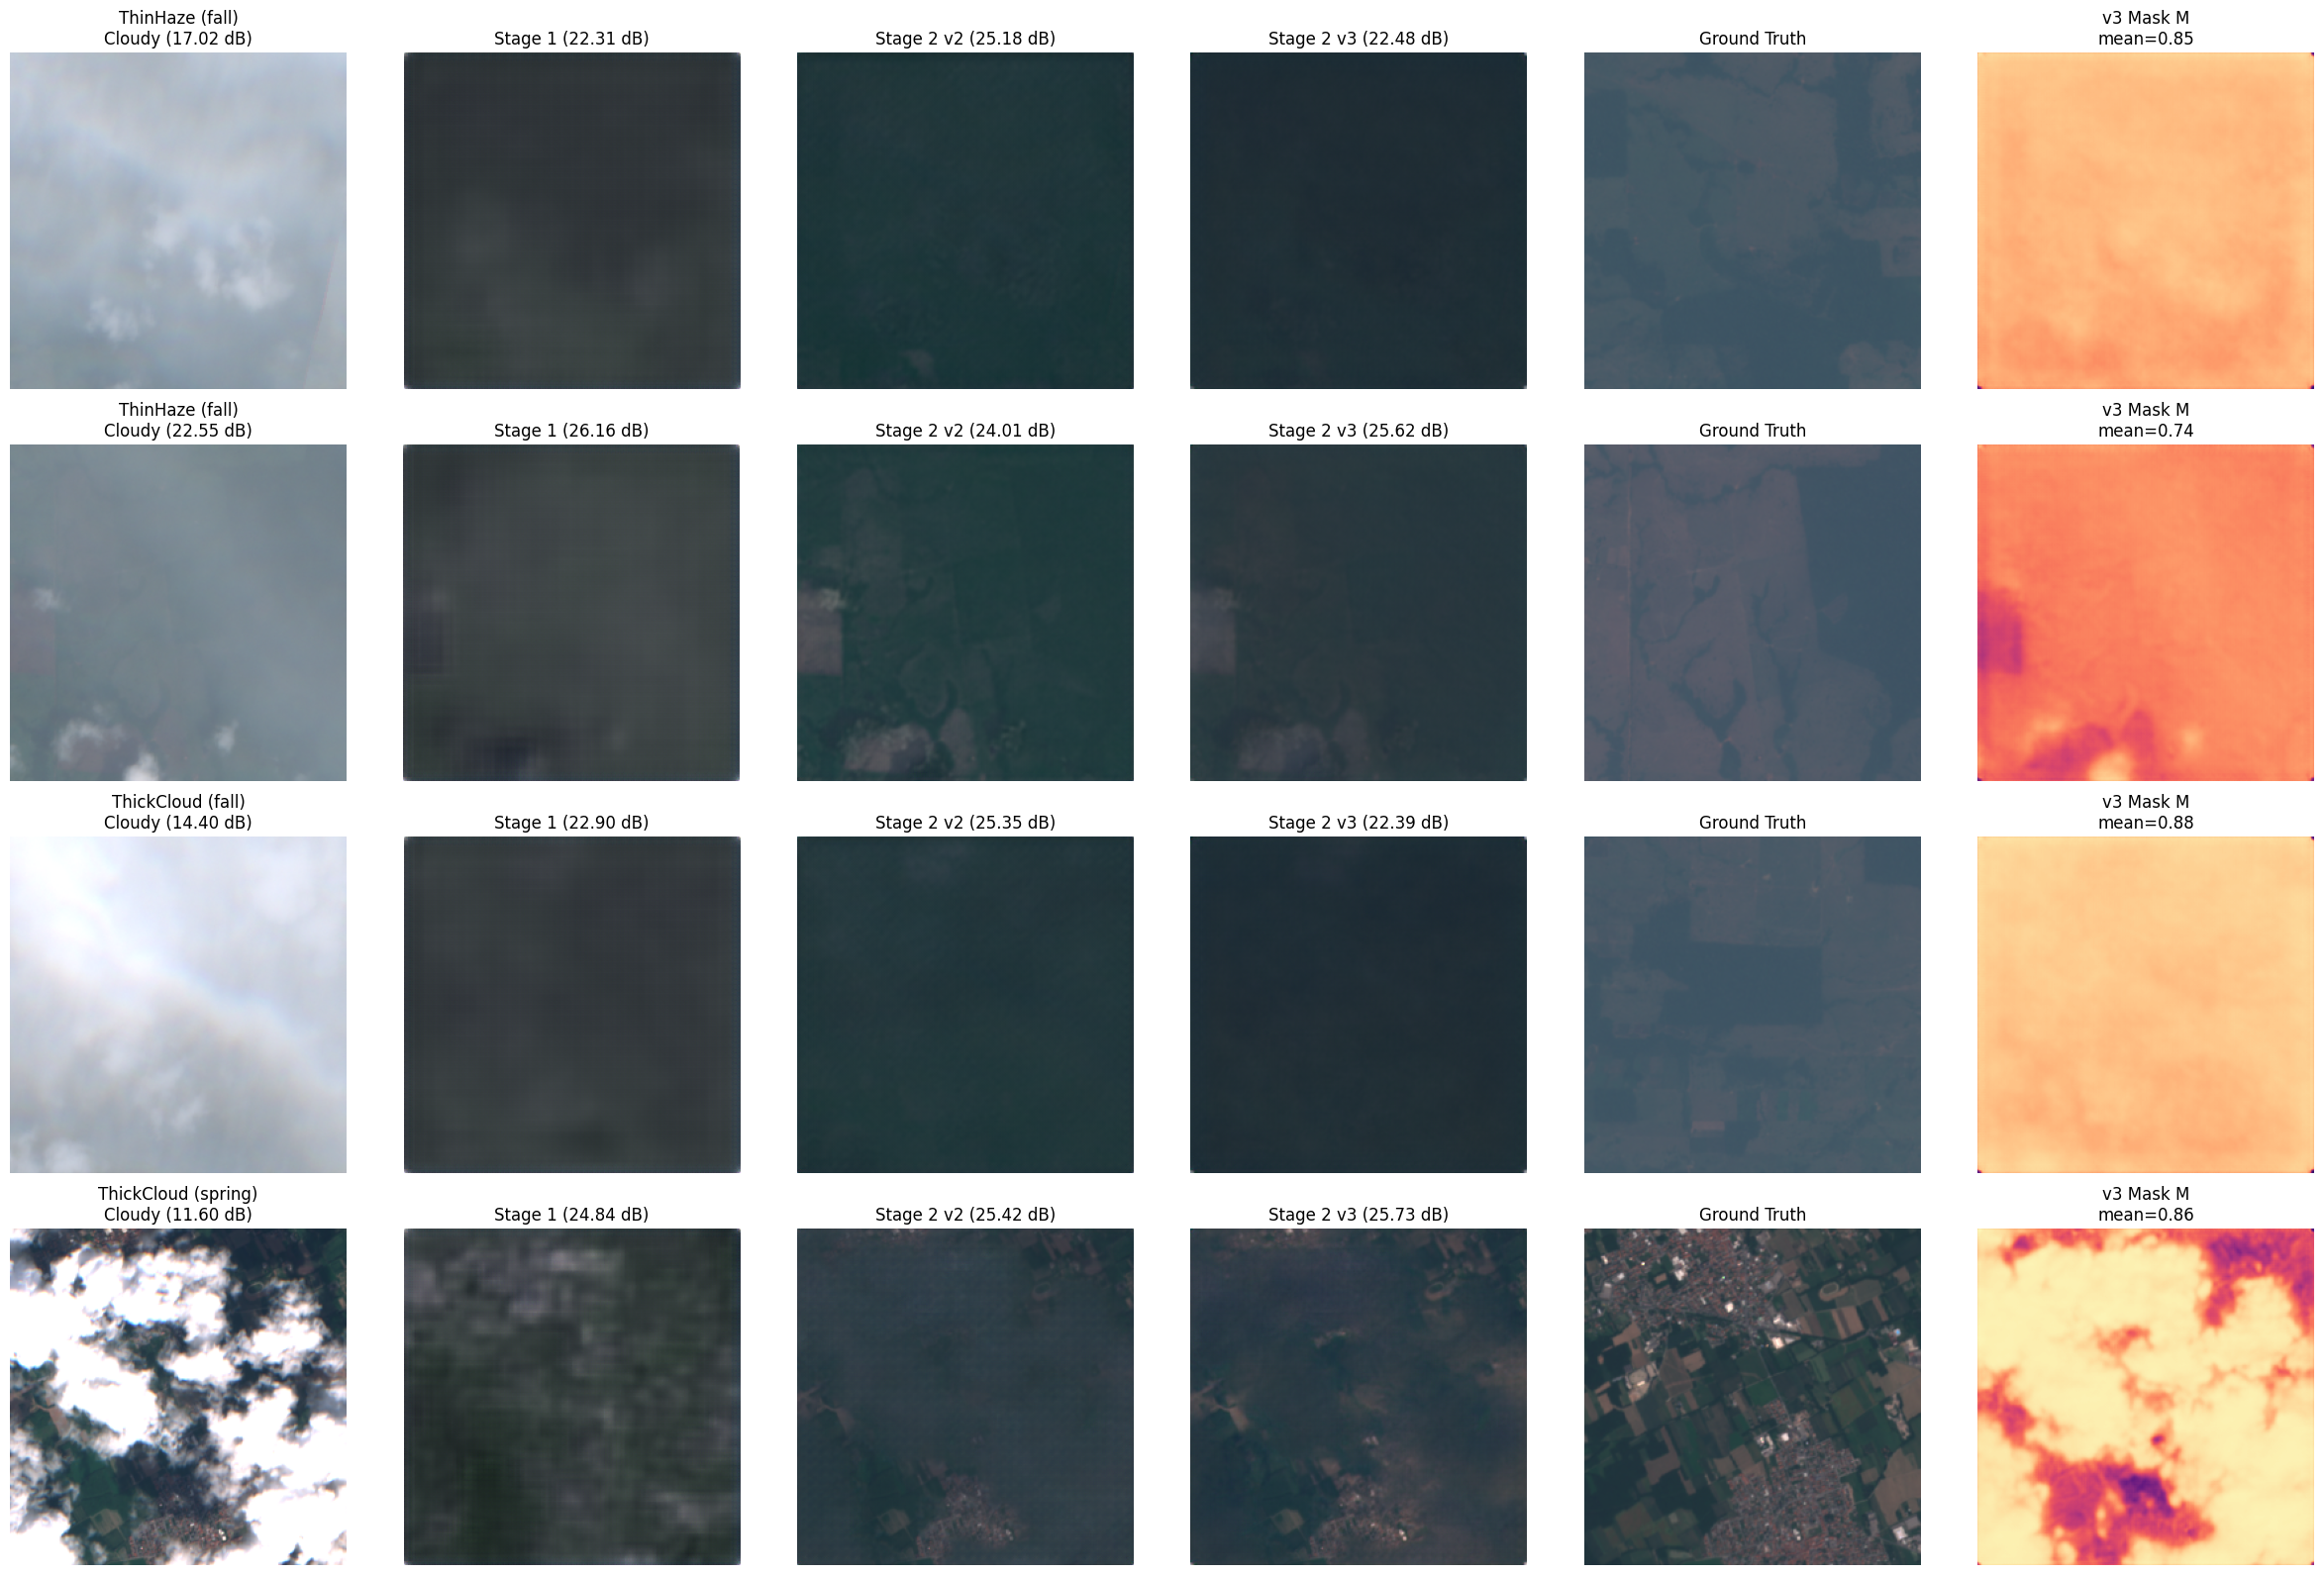

In [6]:
import os, glob, sys, shutil, torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from huggingface_hub import HfApi, hf_hub_download

sys.path.append('/kaggle/working/SEN12MS-CR-Cloud-Removal')
from src.models.latent_compression import SatelliteVAE
from src.models.flow_matching import MambaVectorFieldPredictor
from src.models.inference import SARGuidedCloudRemovalPipeline
from src.models.refiner import ResConvBlock, RefinementUNetV3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Inline V2 definition for direct side-by-side comparison
class RefinementUNetV2(nn.Module):
    def __init__(self, base_ch=48):
        super().__init__()
        self.enc1 = ResConvBlock(21, base_ch)
        self.down1 = nn.Conv2d(base_ch, base_ch * 2, 3, stride=2, padding=1)
        self.enc2 = ResConvBlock(base_ch * 2, base_ch * 2)
        self.down2 = nn.Conv2d(base_ch * 2, base_ch * 4, 3, stride=2, padding=1)
        self.enc3 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.down3 = nn.Conv2d(base_ch * 4, base_ch * 4, 3, stride=2, padding=1)
        self.mid1 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.mid2 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.up3 = nn.ConvTranspose2d(base_ch * 4, base_ch * 4, 4, stride=2, padding=1)
        self.dec3 = ResConvBlock(base_ch * 8, base_ch * 4)
        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, stride=2, padding=1)
        self.dec2 = ResConvBlock(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, stride=2, padding=1)
        self.dec1 = ResConvBlock(base_ch * 2, base_ch)
        self.mask_head = nn.Conv2d(base_ch, 1, 3, padding=1)
        self.delta_head = nn.Conv2d(base_ch, 4, 3, padding=1)

    def forward(self, stage1_pred, opt_cloudy_13, sar_norm):
        sar_5x5 = F.avg_pool2d(sar_norm, 5, stride=1, padding=2)
        x = torch.cat([stage1_pred, opt_cloudy_13, sar_norm, sar_5x5], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        m = self.mid2(self.mid1(self.down3(e3)))
        d3 = self.dec3(torch.cat([self.up3(m), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        mask = torch.sigmoid(self.mask_head(d1))
        base = (1.0 - mask) * opt_cloudy_13[:, [1, 2, 3, 7]] + mask * stage1_pred
        return torch.clamp(base + self.delta_head(d1), -1.0, 1.0)

v2_matches = glob.glob("/kaggle/**/mamba_flow_stage2_v2_FINAL.pth", recursive=True)
v3_matches = glob.glob("/kaggle/**/mamba_flow_stage2_v3_FINAL.pth", recursive=True)
if not v3_matches:
    raise FileNotFoundError("Attach the completed v3 notebook output via '+ Add Input' first.")

print(f"V2: {v2_matches[0]}\nV3: {v3_matches[0]}")
ckpt_v2 = torch.load(v2_matches[0], map_location=device, weights_only=True)
ckpt_v3 = torch.load(v3_matches[0], map_location=device, weights_only=True)

vae = SatelliteVAE(opt_channels=4, sar_channels=2, latent_dim=8).to(device)
predictor = MambaVectorFieldPredictor(latent_dim=8, hidden_dim=128).to(device)
refiner_v2 = RefinementUNetV2(base_ch=48).to(device)
refiner_v3 = RefinementUNetV3(base_ch=48).to(device)

vae.load_state_dict(ckpt_v3["vae_state"])
predictor.load_state_dict(ckpt_v3["predictor_state"])
refiner_v2.load_state_dict(ckpt_v2["refiner_state"])
refiner_v3.load_state_dict(ckpt_v3["refiner_state"])

stage1 = SARGuidedCloudRemovalPipeline(vae, predictor, steps=10).to(device).eval()
refiner_v2.eval()
refiner_v3.eval()

# Hook v3 mask_head and color_head for diagnostics
cache = {}
h1 = refiner_v3.mask_head.register_forward_hook(lambda m, i, o: cache.__setitem__("mask", torch.sigmoid(o).detach().cpu()))
h2 = refiner_v3.color_head.register_forward_hook(lambda m, i, o: cache.__setitem__("color", (0.15 * torch.tanh(o)).detach().cpu()))

def calc_psnr(a, b):
    mse = torch.mean((a - b) ** 2).item()
    return float('inf') if mse == 0 else 10.0 * np.log10(1.0 / mse)

def to_rgb(t, gain=2.5):
    img = (t.clamp(-1, 1) + 1) / 2
    return np.clip(img[[2, 1, 0]].permute(1, 2, 0).cpu().numpy() * gain, 0, 1)

parquet_files = sorted(
    f for f in HfApi().list_repo_files("Hermanni/sen12mscr", repo_type="dataset")
    if f.endswith(".parquet")
)

candidate_indices = [40, 80, 120, 15, 65, 105]
thin_haze, thick_cloud = [], []

for idx in candidate_indices:
    if len(thin_haze) >= 2 and len(thick_cloud) >= 2:
        break
    shard = parquet_files[idx % len(parquet_files)]
    shutil.rmtree("/tmp/hf_eval_cache", ignore_errors=True)
    local_pq = hf_hub_download("Hermanni/sen12mscr", filename=shard, repo_type="dataset", cache_dir="/tmp/hf_eval_cache")
    pf = pq.ParquetFile(local_pq)

    checked = 0
    for batch in pf.iter_batches(batch_size=16):
        for row in batch.to_pylist():
            checked += 1
            clear = np.frombuffer(row["target"], dtype=np.int16).reshape(row["opt_shape"])
            t_01 = np.clip(clear[:, :, [1, 2, 3, 7]].astype(np.float32) / 10000.0, 0, 1)
            if t_01.std() < 0.055:
                continue
            cloudy = np.frombuffer(row["cloudy"], dtype=np.int16).reshape(row["opt_shape"])
            c_01 = np.clip(cloudy[:, :, [1, 2, 3, 7]].astype(np.float32) / 10000.0, 0, 1)
            psnr = 10.0 * np.log10(1.0 / (float(np.mean((c_01 - t_01) ** 2)) + 1e-12))
            if 17.0 <= psnr <= 28.0 and len(thin_haze) < 2:
                thin_haze.append((f"ThinHaze ({shard.split('/')[0]})", row))
                break
            elif psnr <= 14.5 and len(thick_cloud) < 2:
                thick_cloud.append((f"ThickCloud ({shard.split('/')[0]})", row))
                break
        if checked >= 64 or (len(thin_haze) >= 2 and len(thick_cloud) >= 2):
            break

shutil.rmtree("/tmp/hf_eval_cache", ignore_errors=True)
selected = thin_haze + thick_cloud

fig, axes = plt.subplots(len(selected), 6, figsize=(24, 4 * len(selected)))
if len(selected) == 1:
    axes = axes[None, :]

with torch.no_grad():
    for i, (label, sample) in enumerate(selected):
        sar = np.frombuffer(sample["sar"], dtype=np.float32).reshape(sample["sar_shape"])
        cloudy = np.frombuffer(sample["cloudy"], dtype=np.int16).reshape(sample["opt_shape"])
        clear = np.frombuffer(sample["target"], dtype=np.int16).reshape(sample["opt_shape"])

        sar_t = torch.from_numpy(sar.copy()).float()
        if sar_t.shape[-1] == 2:
            sar_t = sar_t.permute(2, 0, 1)
        sar_norm = (torch.clamp(sar_t, -25.0, 0.0) / 12.5 + 1.0).unsqueeze(0).to(device)

        cloudy_13 = torch.clamp(torch.from_numpy(cloudy.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device) / 10000.0, 0, 1) * 2 - 1
        clear_4   = (torch.clamp(torch.from_numpy(clear.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device) / 10000.0, 0, 1) * 2 - 1)[:, [1, 2, 3, 7]]
        cloudy_4  = cloudy_13[:, [1, 2, 3, 7]]

        s1_pred = stage1(cloudy_4, sar_norm).clamp(-1.0, 1.0)
        v2_pred = refiner_v2(s1_pred, cloudy_13, sar_norm)
        v3_pred = refiner_v3(s1_pred, cloudy_13, sar_norm)

        m = cache["mask"][0, 0].numpy()
        col_shift = cache["color"].abs().mean().item()

        c_01, t_01 = (cloudy_4 + 1) / 2, (clear_4 + 1) / 2
        s1_01, v2_01, v3_01 = (s1_pred + 1) / 2, (v2_pred + 1) / 2, (v3_pred + 1) / 2

        p_c, p_s1 = calc_psnr(c_01, t_01), calc_psnr(s1_01, t_01)
        p_v2, p_v3 = calc_psnr(v2_01, t_01), calc_psnr(v3_01, t_01)

        print(f"{label:20s} | Cloudy: {p_c:5.2f} | S1: {p_s1:5.2f} | V2: {p_v2:5.2f} | V3: {p_v3:5.2f} dB "
              f"(ΔV2={p_v3-p_v2:+.2f}) | std V2={v2_01.std():.4f} V3={v3_01.std():.4f} GT={t_01.std():.4f} "
              f"| M={m.mean():.2f} [{m.min():.2f},{m.max():.2f}] | ColorΔ={col_shift:.4f}")

        axes[i, 0].imshow(to_rgb(cloudy_4[0])); axes[i, 0].set_title(f"{label}\nCloudy ({p_c:.2f} dB)")
        axes[i, 1].imshow(to_rgb(s1_pred[0]));  axes[i, 1].set_title(f"Stage 1 ({p_s1:.2f} dB)")
        axes[i, 2].imshow(to_rgb(v2_pred[0]));  axes[i, 2].set_title(f"Stage 2 v2 ({p_v2:.2f} dB)")
        axes[i, 3].imshow(to_rgb(v3_pred[0]));  axes[i, 3].set_title(f"Stage 2 v3 ({p_v3:.2f} dB)")
        axes[i, 4].imshow(to_rgb(clear_4[0]));  axes[i, 4].set_title("Ground Truth")
        axes[i, 5].imshow(m, cmap='magma', vmin=0, vmax=1); axes[i, 5].set_title(f"v3 Mask M\nmean={m.mean():.2f}")
        for ax in axes[i]: ax.axis('off')

h1.remove()
h2.remove()
plt.tight_layout()
plt.show()

In [8]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lpips"], check=True)

import os, glob, json, time, shutil, zipfile, csv, torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
import lpips
from huggingface_hub import HfApi, hf_hub_download
from skimage.metrics import structural_similarity as ssim_fn

sys.path.append('/kaggle/working/SEN12MS-CR-Cloud-Removal')
from src.models.latent_compression import SatelliteVAE
from src.models.flow_matching import MambaVectorFieldPredictor
from src.models.inference import SARGuidedCloudRemovalPipeline
from src.models.refiner import ResConvBlock, RefinementUNetV3

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT_DIR = "/kaggle/working/paper_artifacts"
shutil.rmtree(OUT_DIR, ignore_errors=True)
os.makedirs(OUT_DIR, exist_ok=True)


# --- 1. Inline V2 Definition + Model Loading ---
class RefinementUNetV2(nn.Module):
    def __init__(self, base_ch=48):
        super().__init__()
        self.enc1 = ResConvBlock(21, base_ch)
        self.down1 = nn.Conv2d(base_ch, base_ch * 2, 3, stride=2, padding=1)
        self.enc2 = ResConvBlock(base_ch * 2, base_ch * 2)
        self.down2 = nn.Conv2d(base_ch * 2, base_ch * 4, 3, stride=2, padding=1)
        self.enc3 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.down3 = nn.Conv2d(base_ch * 4, base_ch * 4, 3, stride=2, padding=1)
        self.mid1 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.mid2 = ResConvBlock(base_ch * 4, base_ch * 4)
        self.up3 = nn.ConvTranspose2d(base_ch * 4, base_ch * 4, 4, stride=2, padding=1)
        self.dec3 = ResConvBlock(base_ch * 8, base_ch * 4)
        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, stride=2, padding=1)
        self.dec2 = ResConvBlock(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, stride=2, padding=1)
        self.dec1 = ResConvBlock(base_ch * 2, base_ch)
        self.mask_head = nn.Conv2d(base_ch, 1, 3, padding=1)
        self.delta_head = nn.Conv2d(base_ch, 4, 3, padding=1)

    def forward(self, stage1_pred, opt_cloudy_13, sar_norm):
        sar_5x5 = F.avg_pool2d(sar_norm, 5, stride=1, padding=2)
        x = torch.cat([stage1_pred, opt_cloudy_13, sar_norm, sar_5x5], dim=1)
        e1 = self.enc1(x)
        e2 = self.enc2(self.down1(e1))
        e3 = self.enc3(self.down2(e2))
        m = self.mid2(self.mid1(self.down3(e3)))
        d3 = self.dec3(torch.cat([self.up3(m), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        mask = torch.sigmoid(self.mask_head(d1))
        base = (1.0 - mask) * opt_cloudy_13[:, [1, 2, 3, 7]] + mask * stage1_pred
        return torch.clamp(base + self.delta_head(d1), -1.0, 1.0)


v2_matches = glob.glob("/kaggle/**/mamba_flow_stage2_v2_FINAL.pth", recursive=True)
v3_matches = glob.glob("/kaggle/**/mamba_flow_stage2_v3_FINAL.pth", recursive=True)
if not v2_matches or not v3_matches:
    raise FileNotFoundError(f"Missing checkpoints. Found v2={v2_matches}, v3={v3_matches}")

v2_path, v3_path = v2_matches[0], v3_matches[0]
print(f"V2: {v2_path}\nV3: {v3_path}")

ckpt_v2 = torch.load(v2_path, map_location=device, weights_only=True)
ckpt_v3 = torch.load(v3_path, map_location=device, weights_only=True)

vae = SatelliteVAE(opt_channels=4, sar_channels=2, latent_dim=8).to(device)
predictor = MambaVectorFieldPredictor(latent_dim=8, hidden_dim=128).to(device)
refiner_v2 = RefinementUNetV2(base_ch=48).to(device)
refiner_v3 = RefinementUNetV3(base_ch=48).to(device)

vae.load_state_dict(ckpt_v3["vae_state"])
predictor.load_state_dict(ckpt_v3["predictor_state"])
refiner_v2.load_state_dict(ckpt_v2["refiner_state"])
refiner_v3.load_state_dict(ckpt_v3["refiner_state"])

stage1 = SARGuidedCloudRemovalPipeline(vae, predictor, steps=10).to(device).eval()
refiner_v2.eval()
refiner_v3.eval()
lpips_fn = lpips.LPIPS(net='alex').to(device).eval()

mask_cache = {}
hook = refiner_v3.mask_head.register_forward_hook(
    lambda m, i, o: mask_cache.__setitem__("mask", torch.sigmoid(o).detach().cpu())
)


# --- 2. Weight-Space Audit & Latency Profiling ---
def audit_refiner(state_dict):
    w = state_dict["enc1.conv1.weight"].detach().cpu().float()
    norms = w.flatten(2).norm(dim=(0, 2))
    max_w = max(v.abs().max().item() for v in state_dict.values())
    return {
        "stage1_norm_mean": round(norms[0:4].mean().item(), 4),
        "opt13_norm_mean": round(norms[4:17].mean().item(), 4),
        "raw_sar_norm_mean": round(norms[17:19].mean().item(), 4),
        "despeckled_5x5_sar_norm_mean": round(norms[19:21].mean().item(), 4),
        "max_weight_magnitude": round(max_w, 4),
    }

weight_audit = {
    "stage2_v2": audit_refiner(ckpt_v2["refiner_state"]),
    "stage2_v3": audit_refiner(ckpt_v3["refiner_state"]),
}
with open(f"{OUT_DIR}/weight_audit.json", "w") as f:
    json.dump(weight_audit, f, indent=2)

param_counts = {
    "stage1_vae": sum(p.numel() for p in vae.parameters()),
    "stage1_mamba_predictor": sum(p.numel() for p in predictor.parameters()),
    "stage2_v2_refiner": sum(p.numel() for p in refiner_v2.parameters()),
    "stage2_v3_refiner": sum(p.numel() for p in refiner_v3.parameters()),
}

# Latency benchmark (ms/tile)
with torch.no_grad():
    d_c4 = torch.zeros(1, 4, 256, 256, device=device)
    d_c13 = torch.zeros(1, 13, 256, 256, device=device)
    d_sar = torch.zeros(1, 2, 256, 256, device=device)
    for _ in range(10):
        s1_d = stage1(d_c4, d_sar)
        _ = refiner_v2(s1_d, d_c13, d_sar)
        _ = refiner_v3(s1_d, d_c13, d_sar)
    if device.type == "cuda": torch.cuda.synchronize()

    t0 = time.perf_counter()
    for _ in range(30):
        s1_d = stage1(d_c4, d_sar)
    if device.type == "cuda": torch.cuda.synchronize()
    ms_s1 = (time.perf_counter() - t0) * 1000.0 / 30.0

    t0 = time.perf_counter()
    for _ in range(30):
        _ = refiner_v2(s1_d, d_c13, d_sar)
    if device.type == "cuda": torch.cuda.synchronize()
    ms_v2 = (time.perf_counter() - t0) * 1000.0 / 30.0

    t0 = time.perf_counter()
    for _ in range(30):
        _ = refiner_v3(s1_d, d_c13, d_sar)
    if device.type == "cuda": torch.cuda.synchronize()
    ms_v3 = (time.perf_counter() - t0) * 1000.0 / 30.0

latency_ms = {
    "stage1_only_ms": round(ms_s1, 2),
    "stage2_v2_only_ms": round(ms_v2, 2),
    "stage2_v3_only_ms": round(ms_v3, 2),
    "full_pipeline_v2_ms": round(ms_s1 + ms_v2, 2),
    "full_pipeline_v3_ms": round(ms_s1 + ms_v3, 2),
}


# --- 3. Metric Functions ---
def compute_metrics(pred_01, gt_01):
    # pred_01, gt_01: (1, 4, 256, 256) on GPU in [0, 1]
    diff = pred_01 - gt_01
    mse = torch.mean(diff ** 2).item()
    psnr = 10.0 * np.log10(1.0 / (mse + 1e-12))
    mae = torch.mean(diff.abs()).item()
    rmse = float(np.sqrt(mse))

    # Spectral Angle Mapper (SAM) in degrees across 4 bands
    p_vec = pred_01[0].reshape(4, -1)
    g_vec = gt_01[0].reshape(4, -1)
    dot = (p_vec * g_vec).sum(dim=0)
    denom = p_vec.norm(dim=0) * g_vec.norm(dim=0) + 1e-8
    cos_sim = torch.clamp(dot / denom, -1.0, 1.0)
    sam_deg = float(torch.acos(cos_sim).mean().item() * (180.0 / np.pi))

    # RGB SSIM
    p_rgb = pred_01[0, [2, 1, 0]].permute(1, 2, 0).cpu().numpy()
    g_rgb = gt_01[0, [2, 1, 0]].permute(1, 2, 0).cpu().numpy()
    ssim = float(ssim_fn(p_rgb, g_rgb, data_range=1.0, channel_axis=2))

    # LPIPS on 2.5x gained RGB in [-1, 1]
    p_lp = torch.clamp(pred_01[:, [2, 1, 0]] * 2.5, 0.0, 1.0) * 2.0 - 1.0
    g_lp = torch.clamp(gt_01[:, [2, 1, 0]] * 2.5, 0.0, 1.0) * 2.0 - 1.0
    lp = float(lpips_fn(p_lp, g_lp).item())

    return {"psnr": psnr, "ssim": ssim, "sam": sam_deg, "mae": mae, "rmse": rmse, "lpips": lp}

def to_rgb(t, gain=2.5):
    img = (t.clamp(-1, 1) + 1) / 2
    return np.clip(img[[2, 1, 0]].permute(1, 2, 0).cpu().numpy() * gain, 0, 1)


# --- 4. 100-Tile Multi-Season Evaluation ---
parquet_files = sorted(
    f for f in HfApi().list_repo_files("Hermanni/sen12mscr", repo_type="dataset")
    if f.endswith(".parquet")
)
test_shards = [f for f in parquet_files if "test" in f.lower()]
if test_shards:
    selected_shards = test_shards[:5]
    split_note = "Official test shards found"
else:
    eval_shard_indices = [12, 48, 86, 118, 142]
    selected_shards = [parquet_files[i % len(parquet_files)] for i in eval_shard_indices]
    split_note = "No dedicated test folder in HF repo; 5 fixed multi-season shards (20 tiles each)"

manifest = {"repo": "Hermanni/sen12mscr", "split_note": split_note, "shards": selected_shards, "tiles": []}
csv_rows = []
visual_thin, visual_thick = [], []

with torch.no_grad():
    for shard in selected_shards:
        print(f"Evaluating shard: {shard} ...")
        shutil.rmtree("/tmp/hf_eval_cache", ignore_errors=True)
        local_pq = hf_hub_download("Hermanni/sen12mscr", filename=shard, repo_type="dataset", cache_dir="/tmp/hf_eval_cache")
        pf = pq.ParquetFile(local_pq)

        taken = 0
        for batch in pf.iter_batches(batch_size=16):
            for row in batch.to_pylist():
                if taken >= 20:
                    break
                sar = np.frombuffer(row["sar"], dtype=np.float32).reshape(row["sar_shape"])
                cloudy = np.frombuffer(row["cloudy"], dtype=np.int16).reshape(row["opt_shape"])
                clear = np.frombuffer(row["target"], dtype=np.int16).reshape(row["opt_shape"])

                sar_t = torch.from_numpy(sar.copy()).float()
                if sar_t.shape[-1] == 2:
                    sar_t = sar_t.permute(2, 0, 1)
                sar_norm = (torch.clamp(sar_t, -25.0, 0.0) / 12.5 + 1.0).unsqueeze(0).to(device)

                cloudy_13 = torch.clamp(torch.from_numpy(cloudy.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device) / 10000.0, 0, 1) * 2 - 1
                clear_4   = (torch.clamp(torch.from_numpy(clear.copy()).permute(2, 0, 1).unsqueeze(0).float().to(device) / 10000.0, 0, 1) * 2 - 1)[:, [1, 2, 3, 7]]
                cloudy_4  = cloudy_13[:, [1, 2, 3, 7]]

                s1_pred = stage1(cloudy_4, sar_norm).clamp(-1.0, 1.0)
                v2_pred = refiner_v2(s1_pred, cloudy_13, sar_norm)
                v3_pred = refiner_v3(s1_pred, cloudy_13, sar_norm)
                m_np = mask_cache["mask"][0, 0].numpy()

                c_01, t_01 = (cloudy_4 + 1) / 2, (clear_4 + 1) / 2
                s1_01, v2_01, v3_01 = (s1_pred + 1) / 2, (v2_pred + 1) / 2, (v3_pred + 1) / 2

                mc = compute_metrics(c_01, t_01)
                m1 = compute_metrics(s1_01, t_01)
                m2 = compute_metrics(v2_01, t_01)
                m3 = compute_metrics(v3_01, t_01)
                regime = "thin" if mc["psnr"] >= 17.0 else "thick"

                manifest["tiles"].append({"shard": shard, "row_idx": taken, "regime": regime})
                row_dict = {"shard": shard, "row_idx": taken, "regime": regime, "mask_mean": round(float(m_np.mean()), 4)}
                for prefix, md in [("cloudy", mc), ("s1", m1), ("v2", m2), ("v3", m3)]:
                    for k, v in md.items():
                        row_dict[f"{prefix}_{k}"] = round(v, 5)
                csv_rows.append(row_dict)

                # Collect 2 Thin + 2 Thick high-contrast land tiles for 300-DPI figure
                if t_01.std().item() >= 0.055:
                    vv_5 = F.avg_pool2d(sar_t[0:1].unsqueeze(0), 5, stride=1, padding=2)[0, 0].numpy()
                    sar_disp = np.clip((vv_5 - np.percentile(vv_5, 2)) / (np.percentile(vv_5, 98) - np.percentile(vv_5, 2) + 1e-6), 0, 1)
                    entry = {
                        "label": f"{'Thin' if regime=='thin' else 'Thick'} ({shard.split('/')[0]})",
                        "shard": shard, "sar": sar_disp, "cloudy": to_rgb(cloudy_4[0]),
                        "s1": to_rgb(s1_pred[0]), "v2": to_rgb(v2_pred[0]), "v3": to_rgb(v3_pred[0]),
                        "gt": to_rgb(clear_4[0]), "mask": m_np,
                        "mc": mc, "m1": m1, "m2": m2, "m3": m3
                    }
                    if regime == "thin" and len(visual_thin) < 2 and not any(x["shard"] == shard for x in visual_thin):
                        visual_thin.append(entry)
                    elif regime == "thick" and len(visual_thick) < 2 and not any(x["shard"] == shard for x in visual_thick):
                        visual_thick.append(entry)
                taken += 1
            if taken >= 20:
                break

shutil.rmtree("/tmp/hf_eval_cache", ignore_errors=True)
hook.remove()

# --- 5. Save CSV, Manifest & Aggregated Summary JSON ---
with open(f"{OUT_DIR}/eval_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

with open(f"{OUT_DIR}/test_metrics.csv", "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(csv_rows[0].keys()))
    writer.writeheader()
    writer.writerows(csv_rows)

def agg(rows_subset):
    out = {"n": len(rows_subset)}
    for prefix in ["cloudy", "s1", "v2", "v3"]:
        out[prefix] = {}
        for k in ["psnr", "ssim", "sam", "mae", "rmse", "lpips"]:
            vals = [r[f"{prefix}_{k}"] for r in rows_subset]
            out[prefix][k] = {"mean": round(float(np.mean(vals)), 4), "std": round(float(np.std(vals)), 4)}
    return out

summary = {
    "all_100": agg(csv_rows),
    "thin_haze": agg([r for r in csv_rows if r["regime"] == "thin"]),
    "thick_cloud": agg([r for r in csv_rows if r["regime"] == "thick"]),
    "parameters": param_counts,
    "latency_ms": latency_ms,
    "weight_audit": weight_audit,
}
with open(f"{OUT_DIR}/test_summary.json", "w") as f:
    json.dump(summary, f, indent=2)


# --- 6. Render 300-DPI Publication Figures ---
visuals = visual_thin + visual_thick
if visuals:
    fig, axes = plt.subplots(len(visuals), 7, figsize=(21, 3.2 * len(visuals)), dpi=300)
    if len(visuals) == 1:
        axes = axes[None, :]
    for i, v in enumerate(visuals):
        axes[i, 0].imshow(v["sar"], cmap="gray"); axes[i, 0].set_title(f"{v['label']}\nSAR VV (5×5)", fontsize=9)
        axes[i, 1].imshow(v["cloudy"]);           axes[i, 1].set_title(f"Cloudy\n{v['mc']['psnr']:.2f} dB | {v['mc']['ssim']:.3f}", fontsize=9)
        axes[i, 2].imshow(v["s1"]);               axes[i, 2].set_title(f"Stage 1\n{v['m1']['psnr']:.2f} dB | {v['m1']['ssim']:.3f}", fontsize=9)
        axes[i, 3].imshow(v["v2"]);               axes[i, 3].set_title(f"Stage 2 v2\n{v['m2']['psnr']:.2f} dB | {v['m2']['ssim']:.3f}", fontsize=9)
        axes[i, 4].imshow(v["v3"]);               axes[i, 4].set_title(f"Stage 2 v3\n{v['m3']['psnr']:.2f} dB | {v['m3']['ssim']:.3f}", fontsize=9)
        axes[i, 5].imshow(v["gt"]);               axes[i, 5].set_title("Ground Truth", fontsize=9)
        axes[i, 6].imshow(v["mask"], cmap="magma", vmin=0, vmax=1); axes[i, 6].set_title(f"v3 Mask M\nmean={v['mask'].mean():.2f}", fontsize=9)
        for ax in axes[i]: ax.axis("off")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/fig_visual_comparison.png", dpi=300, bbox_inches="tight")
    plt.savefig(f"{OUT_DIR}/fig_visual_comparison.pdf", bbox_inches="tight")
    plt.close()

# Ablation bar chart
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=300)
regimes = ["all_100", "thin_haze", "thick_cloud"]
r_labels = [f"All (n={summary['all_100']['n']})", f"Thin (n={summary['thin_haze']['n']})", f"Thick (n={summary['thick_cloud']['n']})"]
x = np.arange(len(regimes))
w = 0.2
for idx, (key, name) in enumerate([("cloudy", "Cloudy"), ("s1", "Stage 1"), ("v2", "Stage 2 v2"), ("v3", "Stage 2 v3")]):
    ax1.bar(x + (idx - 1.5) * w, [summary[r][key]["psnr"]["mean"] for r in regimes], w, label=name)
    ax2.bar(x + (idx - 1.5) * w, [summary[r][key]["ssim"]["mean"] for r in regimes], w, label=name)
ax1.set_xticks(x); ax1.set_xticklabels(r_labels); ax1.set_ylabel("PSNR (dB) ↑"); ax1.set_title("PSNR Across Cloud Regimes"); ax1.legend(fontsize=8); ax1.grid(axis="y", alpha=0.3)
ax2.set_xticks(x); ax2.set_xticklabels(r_labels); ax2.set_ylabel("SSIM ↑"); ax2.set_title("SSIM Across Cloud Regimes"); ax2.set_ylim(0.35, 1.02); ax2.legend(fontsize=8); ax2.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_ablation_tradeoff.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{OUT_DIR}/fig_ablation_tradeoff.pdf", bbox_inches="tight")
plt.close()

# --- 7. Zip Everything for Download ---
zip_path = "/kaggle/working/paper_artifacts.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(OUT_DIR):
        for fn in files:
            full = os.path.join(root, fn)
            zf.write(full, arcname=os.path.relpath(full, OUT_DIR))

print(f"\nSaved all artifacts to: {zip_path}")
print("\n=== PAPER-GRADE SUMMARY (ALL 100 TILES) ===")
print(f"{'Model':12s} | {'PSNR (dB) ↑':14s} | {'SSIM ↑':13s} | {'SAM (°) ↓':12s} | {'MAE ↓':11s} | {'LPIPS ↓':11s}")
print("-" * 86)
for key, name in [("cloudy", "Cloudy"), ("s1", "Stage 1"), ("v2", "Stage 2 v2"), ("v3", "Stage 2 v3")]:
    s = summary["all_100"][key]
    print(f"{name:12s} | {s['psnr']['mean']:6.3f} ± {s['psnr']['std']:4.2f} | "
          f"{s['ssim']['mean']:.4f} ± {s['ssim']['std']:.3f} | "
          f"{s['sam']['mean']:5.2f} ± {s['sam']['std']:4.2f} | "
          f"{s['mae']['mean']:.4f}      | {s['lpips']['mean']:.4f}")
print("\nParameters:", param_counts)
print("Latency (ms/tile):", latency_ms)

V2: /kaggle/input/datasets/sparksjittery/sen12ms-stage1-weights/mamba_flow_stage2_v2_FINAL.pth
V3: /kaggle/input/notebooks/sparksjittery/ml-x16/mamba_flow_stage2_v3_FINAL.pth
Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 229MB/s] 


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth
Evaluating shard: fall/scene_120.parquet ...


fall/scene_120.parquet: reconstructing file:   0%|          |  0.00B / 2.29GB            

... (10 outputs left out)

Evaluating shard: summer/scene_86.parquet ...


summer/scene_86.parquet: reconstructing file:   0%|          |  0.00B / 2.26GB            

summer/scene_86.parquet: downloading bytes:           |  0.00B            


Saved all artifacts to: /kaggle/working/paper_artifacts.zip

=== PAPER-GRADE SUMMARY (ALL 100 TILES) ===
Model        | PSNR (dB) ↑    | SSIM ↑        | SAM (°) ↓    | MAE ↓       | LPIPS ↓    
--------------------------------------------------------------------------------------
Cloudy       | 19.994 ± 8.39 | 0.6608 ± 0.231 | 10.86 ± 6.90 | 0.1103      | 0.5027
Stage 1      | 27.181 ± 2.26 | 0.8833 ± 0.054 | 10.10 ± 2.87 | 0.0334      | 0.6698
Stage 2 v2   | 32.316 ± 3.58 | 0.9420 ± 0.051 |  5.31 ± 3.92 | 0.0184      | 0.2660
Stage 2 v3   | 31.164 ± 3.76 | 0.9446 ± 0.048 |  5.38 ± 3.16 | 0.0203      | 0.2341

Parameters: {'stage1_vae': 128308, 'stage1_mamba_predictor': 5022344, 'stage2_v2_refiner': 5097797, 'stage2_v3_refiner': 5097993}
Latency (ms/tile): {'stage1_only_ms': 53.22, 'stage2_v2_only_ms': 36.12, 'stage2_v3_only_ms': 39.16, 'full_pipeline_v2_ms': 89.34, 'full_pipeline_v3_ms': 92.38}


In [1]:
import os, zipfile

repo_dir = "/kaggle/working/SEN12MS-CR-Cloud-Removal"
zip_out = "/kaggle/working/source_code_final.zip"

with zipfile.ZipFile(zip_out, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, dirs, files in os.walk(repo_dir):
        dirs[:] = [d for d in dirs if d not in (".git", "__pycache__", ".ipynb_checkpoints")]
        for fn in files:
            if fn.endswith((".py", ".yaml", ".yml", ".txt", ".md", ".json")):
                full = os.path.join(root, fn)
                zf.write(full, arcname=os.path.relpath(full, repo_dir))

print(f"Exported {zip_out}:")
with zipfile.ZipFile(zip_out, "r") as zf:
    for name in sorted(zf.namelist()):
        print(" ", name)

Exported /kaggle/working/source_code_final.zip:
  src/__init__.py
  src/data/__init__.py
  src/data/dataset.py
  src/models/__init__.py
  src/models/flow_matching.py
  src/models/inference.py
  src/models/latent_compression.py
  src/models/mamba_ss2d.py
  src/models/refiner.py
  src/train.py
  src/train_stage1_resume.py
  src/verify_v3.py
  tests/test_data.py
  tests/test_flow_matching.py
  tests/test_inference.py
  tests/test_latent.py
  tests/test_mamba.py
